# Level 3 — Task 1: Restaurant Reviews

### Data Availability Check & Closest Feasible Analysis

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Task as given:**
1. Analyze the text reviews to identify the most common positive and negative
   keywords.
2. Calculate the average length of reviews and explore whether there is a
   relationship between review length and rating.

**Important:** this task needs written review text. The notebook first checks
whether the dataset contains any, and then does the closest analysis the
available data allows.

## 1. Dataset Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [2]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.shape

(9551, 21)

## 2. Does the Dataset Contain Review Text?

In [4]:
text_cols = df.select_dtypes(exclude="number").columns

inventory = pd.DataFrame({
    "Column": text_cols,
    "Unique values": [df[c].nunique() for c in text_cols],
    "Avg length (chars)": [round(df[c].astype(str).str.len().mean(), 1) for c in text_cols],
    "Max length (chars)": [int(df[c].astype(str).str.len().max()) for c in text_cols],
}).sort_values("Max length (chars)", ascending=False).reset_index(drop=True)
inventory

,Column,Unique values,Avg length (chars),Max length (chars)
0,Address,8918,53.5,132
1,Cuisines,1825,19.9,93
2,Locality Verbose,1265,24.2,64
3,Restaurant Name,7446,15.2,54
4,Locality,1208,14.0,51
5,City,141,8.2,22
6,Currency,12,17.4,22
7,Rating color,6,5.7,10
8,Rating text,6,7.0,9
9,Has Online delivery,2,2.3,3


In [5]:
keywords = ["review", "comment", "feedback", "text", "opinion", "description"]
review_like = [c for c in df.columns if any(k in c.lower() for k in keywords)]

print("Columns whose name suggests review text:", review_like)
print("Values in 'Rating text':", df["Rating text"].unique().tolist())
print("Longest 'Rating text' value:", df["Rating text"].str.len().max(), "characters")

Columns whose name suggests review text: ['Rating text']
Values in 'Rating text': ['Excellent', 'Very Good', 'Good', 'Average', 'Not rated', 'Poor']
Longest 'Rating text' value: 9 characters


In [6]:
df.groupby("Rating text")["Aggregate rating"].agg(Min_Rating="min", Max_Rating="max", Restaurants="count")

,Min_Rating,Max_Rating,Restaurants
Rating text,,,
Average,2.5,3.4,3737
Excellent,4.5,4.9,301
Good,3.5,3.9,2100
Not rated,0.0,0.0,2148
Poor,1.8,2.4,186
Very Good,4.0,4.4,1079


### Conclusion

- The longest text columns are `Address` (up to 132 characters) and `Cuisines`
  (up to 93). None of them is a customer review.
- The only opinion-related text column is `Rating text`, and it holds just **six
  fixed labels** (Excellent, Very Good, Good, Average, Poor, Not rated), at most 9
  characters long. The table above shows that each label is simply a band of the
  numeric `Aggregate rating` (for example Excellent = 4.5 to 4.9). `Rating color`
  is the same information again as a colour.

**There is no free-text review in this dataset**, so the two requested analyses
cannot be done honestly:

- **Positive and negative keywords** need the words customers wrote.
- **Average review length and its link with rating** need the length of each
  written review.

Inventing review text would produce meaningless results, so this notebook
instead analyses the **sentiment labels that do exist**.

## 3. Closest Feasible Analysis: Rating Labels as Sentiment

The labels are grouped into a simple sentiment scale: **Positive** (Good, Very
Good, Excellent), **Neutral** (Average) and **Negative** (Poor). This grouping is
a judgement call, and restaurants labelled "Not rated" are left out.

In [7]:
label_order = ["Poor", "Average", "Good", "Very Good", "Excellent"]
sentiment_map = {"Poor": "Negative", "Average": "Neutral", "Good": "Positive",
                 "Very Good": "Positive", "Excellent": "Positive"}

labelled = df[df["Rating text"] != "Not rated"].copy()
labelled["Sentiment"] = labelled["Rating text"].map(sentiment_map)

label_counts = labelled["Rating text"].value_counts().reindex(label_order)
label_table = pd.DataFrame({
    "Rating text": label_counts.index,
    "Restaurants": label_counts.values,
    "% of rated restaurants": (label_counts.values / len(labelled) * 100).round(2),
    "Sentiment": [sentiment_map[l] for l in label_counts.index],
})
print(f"Not rated: {(df['Rating text'] == 'Not rated').sum():,} restaurants (left out)")
label_table

Not rated: 2,148 restaurants (left out)


,Rating text,Restaurants,% of rated restaurants,Sentiment
0,Poor,186,2.51,Negative
1,Average,3737,50.48,Neutral
2,Good,2100,28.37,Positive
3,Very Good,1079,14.58,Positive
4,Excellent,301,4.07,Positive


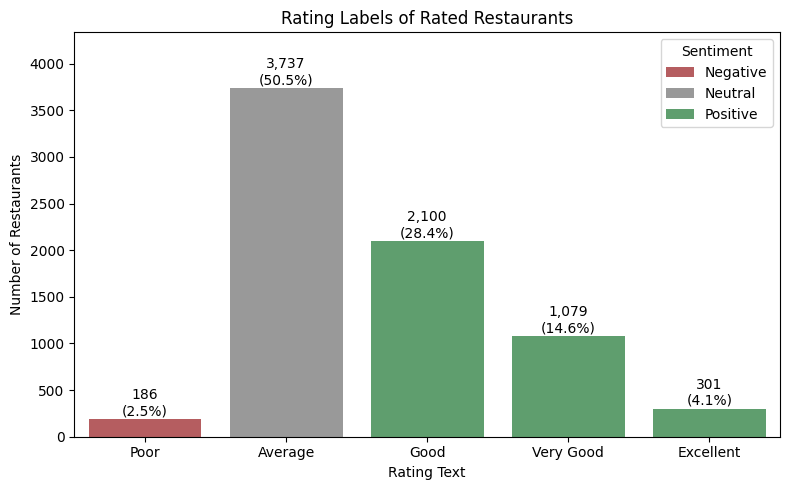

In [8]:
palette = {"Negative": "#C44E52", "Neutral": "#999999", "Positive": "#55A868"}

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=label_table, x="Rating text", y="Restaurants", hue="Sentiment",
                 palette=palette, dodge=False)
for i, (v, p) in enumerate(zip(label_table["Restaurants"], label_table["% of rated restaurants"])):
    ax.text(i, v + 40, f"{v:,}\n({p:.1f}%)", ha="center")
plt.ylim(0, label_table["Restaurants"].max() + 600)
plt.title("Rating Labels of Rated Restaurants")
plt.xlabel("Rating Text")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

In [9]:
sentiment_table = (
    labelled["Sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"])
    .rename("Restaurants").to_frame()
)
sentiment_table["% of rated restaurants"] = (sentiment_table["Restaurants"] / len(labelled) * 100).round(2)
sentiment_table

,Restaurants,% of rated restaurants
Sentiment,,
Positive,3480,47.01
Neutral,3737,50.48
Negative,186,2.51


### Engagement by rating label

Review length cannot be measured, but **votes** show how much customer attention
a restaurant receives, so they are compared across the labels instead.

In [10]:
votes_by_label = (
    labelled.groupby("Rating text")["Votes"].agg(Avg_Votes="mean", Median_Votes="median")
    .reindex(label_order).round(1)
)
votes_by_label

,Avg_Votes,Median_Votes
Rating text,,
Poor,90.7,61.0
Average,48.2,20.0
Good,229.4,121.0
Very Good,520.5,271.0
Excellent,851.8,489.0


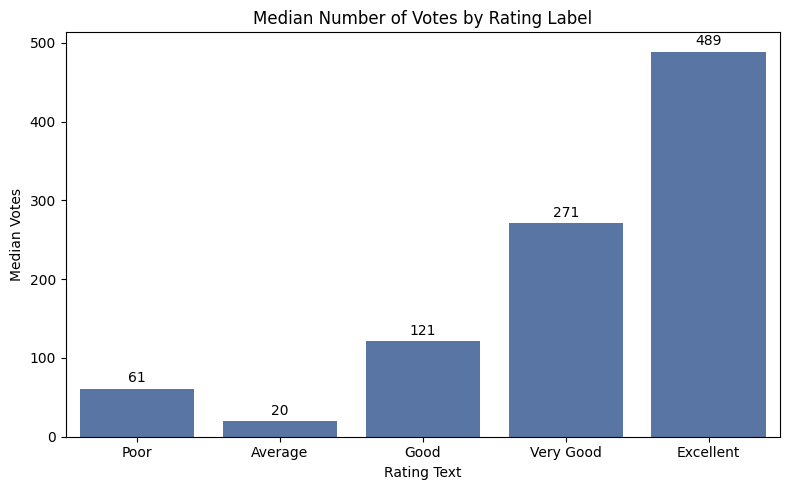

In [11]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=votes_by_label.index, y=votes_by_label["Median_Votes"], color="#4C72B0")
for i, v in enumerate(votes_by_label["Median_Votes"]):
    ax.text(i, v + 8, f"{v:.0f}", ha="center")
plt.title("Median Number of Votes by Rating Label")
plt.xlabel("Rating Text")
plt.ylabel("Median Votes")
plt.tight_layout()
plt.show()

## 4. What Would Be Needed to Complete the Original Task

With a dataset that has one written review per row (for example a `Review`
column plus the rating), the analysis would be:

1. **Keywords:** lowercase and tokenise the reviews, remove stop words, and count
   the most frequent words separately in high-rated (4 and above) and low-rated
   (below 3) reviews to find positive and negative keywords.
2. **Review length:** count words or characters per review, average them, and
   measure the correlation (for example Spearman) between length and rating.

The results of this notebook can be used as context, but they should not be
presented as a review-text analysis.

## 5. Final Results

In [12]:
task_result = pd.DataFrame({
    "Question": [
        "Does the dataset contain review text?",
        "Positive / negative keywords from reviews",
        "Average review length and link with rating",
        "Most common rating label (rated restaurants)",
        "Positive / neutral / negative share of rated restaurants",
        "Median votes: Excellent vs Average",
    ],
    "Answer": [
        "No (only 6 fixed labels in 'Rating text')",
        "Not possible with this data",
        "Not possible with this data",
        f"{label_counts.idxmax()} ({label_counts.max():,} restaurants, {label_counts.max() / len(labelled) * 100:.2f}%)",
        " / ".join(f"{sentiment_table.loc[s, '% of rated restaurants']:.2f}%" for s in ["Positive", "Neutral", "Negative"]),
        f"{votes_by_label.loc['Excellent', 'Median_Votes']:.0f} vs {votes_by_label.loc['Average', 'Median_Votes']:.0f}",
    ],
})
task_result

,Question,Answer
0,Does the dataset contain review text?,No (only 6 fixed labels in 'Rating text')
1,Positive / negative keywords from reviews,Not possible with this data
2,Average review length and link with rating,Not possible with this data
3,Most common rating label (rated restaurants),"Average (3,737 restaurants, 50.48%)"
4,Positive / neutral / negative share of rated r...,47.01% / 50.48% / 2.51%
5,Median votes: Excellent vs Average,489 vs 20


## 6. Validation

In [13]:
print("No column looks like free-text reviews (only 'Rating text'):", review_like == ["Rating text"])
print("Rated restaurants = total - not rated:", len(labelled) == len(df) - (df["Rating text"] == "Not rated").sum())
print("Sentiment groups add up to rated total:", sentiment_table["Restaurants"].sum() == len(labelled))
print("Labels add up to rated total:", label_table["Restaurants"].sum() == len(labelled))

No column looks like free-text reviews (only 'Rating text'): True
Rated restaurants = total - not rated: True
Sentiment groups add up to rated total: True
Labels add up to rated total: True


### Business Insights

**What the data allows**

- **The dataset has no written reviews**, so the requested keyword analysis and
  the review-length analysis cannot be done. The only opinion-related text column
  is `Rating text`, which has six fixed labels that are simply bands of the
  numeric rating.

**Rating labels (closest feasible analysis)**

- **Half of the rated restaurants are "Average".** Of the 7,403 rated
  restaurants, 3,737 (50.48%) are Average, 2,100 (28.37%) Good, 1,079 (14.58%)
  Very Good, 301 (4.07%) Excellent and only 186 (2.51%) Poor.
- **Grouped as sentiment, 47.01% are positive, 50.48% neutral and just 2.51%
  negative.** Ratings are concentrated in the middle and upper part of the
  scale, and very low ratings are rare.
- **Engagement rises with the label.** The median restaurant has 489 votes when
  labelled Excellent, 271 for Very Good, 121 for Good and 20 for Average. This is
  consistent with the votes-vs-rating link found in Task 2.
- **Poor restaurants draw more votes than Average ones** (median 61 vs 20,
  average 90.7 vs 48.2). A possible reason is that restaurants with very few
  votes tend to land in the middle of the scale, but this cannot be tested here.

**Caution**

- The labels are derived from the numeric rating, so they add no new
  information, and the Positive / Neutral / Negative grouping is a judgement
  call.
- 2,148 unrated restaurants are left out.
- This is **not** a review-text analysis. To complete the original task, a
  dataset with the written review of each restaurant is needed.